In [15]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, Literal
from langchain_cohere import ChatCohere
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator

load_dotenv()

True

In [16]:
generator = ChatCohere(
    model="command-r7b-12-2024",
    temperature=1.0
)

evaluator = ChatCohere(
    model="command-a-03-2025",
    temperature=0
)

In [17]:
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(
        description="approved if the tweet is strong enough to post, otherwise needs_improvement"
    )
    feedback: str = Field(
        description="Concrete feedback on hook, clarity, specificity, and virality"
    )

structured_model = evaluator.with_structured_output(TweetEvaluation)

In [18]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int
    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [19]:
def generate(state: TweetState):
    prompt = f"Write a short casual tweet about {state['topic']}. Return only the tweet."
    tweet = generator.invoke(prompt).content.strip()
    return {"tweet": tweet, "tweet_history": [tweet]}


def evaluate(state: TweetState):
    prompt = f"""You are a harsh tweet editor at a top tech account. Default to needs_improvement.
Approve only if ALL of these are true:
- under 280 characters
- a sharp hook in the first few words
- at least one concrete detail (named place, company, number, or event)
- not a generic "AI is transforming India" line
- would actually get replies or quotes

If anything is vague, cliché, or missing a specific detail, return needs_improvement
and say exactly what to fix.

Topic: {state['topic']}
Tweet: {state['tweet']}
"""
    result = structured_model.invoke(prompt)
    return {
        "evaluation": result.evaluation,
        "feedback": result.feedback,
        "feedback_history": [result.feedback],
    }


def optimize(state: TweetState):
    prompt = f"""Rewrite this tweet using the critic's feedback. Keep it under 280 characters.
Return only the improved tweet.

Topic: {state['topic']}
Current tweet: {state['tweet']}
Feedback: {state['feedback']}
Previous tweets: {state['tweet_history']}
"""
    tweet = generator.invoke(prompt).content.strip()
    return {
        "tweet": tweet,
        "iteration": state["iteration"] + 1,
        "tweet_history": [tweet],
    }


def route_evaluation(state: TweetState):
    if state["evaluation"] == "approved" or state["iteration"] >= state["max_iteration"]:
        return END
    return "optimize"

In [20]:
graph = StateGraph(TweetState)

graph.add_node("generate", generate)
graph.add_node("evaluate", evaluate)
graph.add_node("optimize", optimize)

graph.add_edge(START, "generate")
graph.add_edge("generate", "evaluate")
graph.add_conditional_edges("evaluate", route_evaluation, {
    END: END,
    "optimize": "optimize"
})
graph.add_edge("optimize", "evaluate")

workflow = graph.compile()

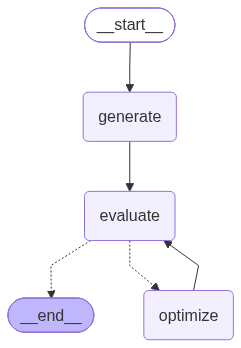

In [21]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [22]:
initial_state = {
    "topic": "AI in India",
    "iteration": 1,
    "max_iteration": 3,
    "tweet_history": [],
    "feedback_history": [],
}

workflow.invoke(initial_state)

{'topic': 'AI in India',
 'tweet': "India's AI sector just hit a milestone: AI startups raised $2.5B in 2023! See how this funding surge is shaping our future at @AIIndiaInnovation. #AIInnovation #TechRevolution",
 'evaluation': 'approved',
 'feedback': 'The tweet meets all criteria: it has a sharp hook, includes a concrete detail ($2.5B in funding), is under 280 characters, avoids generic statements, and is likely to engage replies or quotes.',
 'iteration': 2,
 'max_iteration': 3,
 'tweet_history': ['AI in India is booming! Exciting times ahead as we innovate, create, and lead the way in tech. #AIInnovation #TechRevolution',
  "India's AI sector just hit a milestone: AI startups raised $2.5B in 2023! See how this funding surge is shaping our future at @AIIndiaInnovation. #AIInnovation #TechRevolution"],
 'feedback_history': ["The tweet is too generic and lacks concrete details. Replace 'booming' with a specific statistic or example (e.g., 'AI startups in India raised $2.5B in 2023').